In [1]:
library(here)
library(tidyverse)

# for models
library(lmerTest)

library(ggthemes)
library(svglite)

here() starts at /labs/vislearnlab/experiments/birch-draw

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.6
✔ forcats   1.0.1     ✔ stringr   1.6.0
✔ ggplot2   4.0.1     ✔ tibble    3.3.0
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.2.0     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: lme4

Loading required package: Matrix


Attaching package: ‘Matrix’


The following objects are masked from ‘package:tidyr’:

    expand, pack, unpack



Attaching package: ‘lmerTest’


The following object is masked from ‘package:lme4’:

    lmer


The following object is masked from ‘package:stats’:

    step




In [2]:
# Tidy datasets
drawings_tidy <- read_csv("../data/tidy/drawings.csv")
descriptions_tidy <- read_csv("../data/tidy/utterances.csv")

# Working copies: children only, no interference, artifact must exist
drawings <- drawings_tidy %>%
  filter(is_child, draw_exists == 1, draw_interference == 0)

descriptions <- descriptions_tidy %>%
  filter(is_child, utterance_exists == 1, utterance_interference == 0)

Rows: 638 Columns: 31
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr  (5): participant_id, target_category, bounding_box, draw_full_features,...
dbl (24): age_months, age_yrs, draw_exists, draw_interference, trial_duratio...
lgl  (2): is_adult, is_child

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 638 Columns: 30
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr (10): participant_id, target_category, utterance_ns, utterance_masked, u...
dbl (18): age_months, age_yrs, utterance_exists, utterance_interference, utt...
lgl  (2): is_adult, is_child

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
# Wide form: one row per child × category, with drawing and description similarity
all_data_wide_kids <- drawings %>%
  select(participant_id, age_months, target_category, draw_cossim_adults) %>%
  rename(sub_id = participant_id, category = target_category, drawing_similarity = draw_cossim_adults) %>%
  full_join(
    descriptions %>%
      select(participant_id, age_months, target_category, utterance_full_cossim_adults) %>%
      rename(sub_id = participant_id, category = target_category, description_similarity = utterance_full_cossim_adults),
    by = c("sub_id", "age_months", "category")
  )

# Separate filters: >= 3 valid trials within each modality
kids_filtered_draw <- all_data_wide_kids %>%
  group_by(sub_id) %>%
  filter(sum(!is.na(drawing_similarity)) >= 3) %>%
  ungroup()

kids_filtered_desc <- all_data_wide_kids %>%
  group_by(sub_id) %>%
  filter(sum(!is.na(description_similarity)) >= 3) %>%
  ungroup()

Descriptive plots

In [4]:
# Per-child averages, z-scored within each modality independently
drawing_avgs <- kids_filtered_draw %>%
  group_by(sub_id, age_months) %>%
  summarise(mean_draw_sim = mean(drawing_similarity, na.rm = TRUE), .groups = "drop") %>%
  mutate(drawing_similarity = scale(mean_draw_sim)[, 1])

desc_avgs <- kids_filtered_desc %>%
  group_by(sub_id, age_months) %>%
  summarise(mean_desc_sim = mean(description_similarity, na.rm = TRUE), .groups = "drop") %>%
  mutate(description_similarity = scale(mean_desc_sim)[, 1])

In [5]:
# Shared y-axis and color scale limits across both plots
y_min <- min(c(drawing_avgs$drawing_similarity, desc_avgs$description_similarity), na.rm = TRUE)
y_max <- max(c(drawing_avgs$drawing_similarity, desc_avgs$description_similarity), na.rm = TRUE)

age_min <- min(c(drawing_avgs$age_months, desc_avgs$age_months), na.rm = TRUE) / 12
age_max <- max(c(drawing_avgs$age_months, desc_avgs$age_months), na.rm = TRUE) / 12

Loading required package: viridisLite



`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


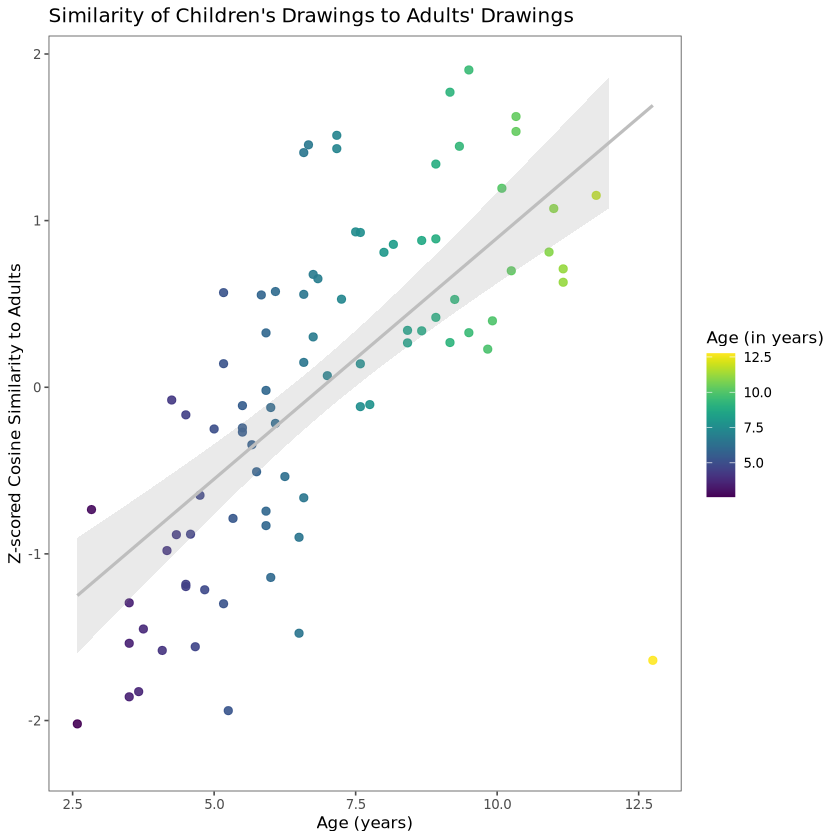

In [6]:
#Drawing accuracy (Fig 3A)
library(viridis)
p_draw <- ggplot(drawing_avgs, aes(x = age_months/12,
                         y = drawing_similarity,
                         col = age_months/12)) +
  geom_point(size = 2, alpha = .9) +
  geom_smooth(method = "lm", color = "grey", alpha = .2) +
  scale_color_viridis(name = "Age (in years)", limits = c(age_min, age_max)) +
  scale_y_continuous(limits = c(y_min, y_max)) +
  labs(
    x = "Age (years)",
    y = "Z-scored Cosine Similarity to Adults",
    title = "Similarity of Children's Drawings to Adults' Drawings"
  ) +
  theme_few(base_size = 10)

p_draw
ggsave('../figures/cds_drawing_sim.png', width = 6, height = 3, units = 'in')

In [7]:
cat("Drawing plot n:", nrow(drawing_avgs), "\n")

Drawing plot n: 85 


Noting that draw_cossim_adults inherently produces NaN values for all adults and we filter to just children here. But want to only z-score within children, not across all participants

In [8]:
draw_model <- lmer(
  scale(draw_cossim_adults)[, 1] ~ age_months + (1 | participant_id) + (1 | target_category),
  data = drawings
)

summary(draw_model)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: scale(draw_cossim_adults)[, 1] ~ age_months + (1 | participant_id) +  
    (1 | target_category)
   Data: drawings

REML criterion at convergence: 1130.6

Scaled residuals: 
     Min       1Q   Median       3Q      Max 
-2.83162 -0.63503 -0.02431  0.62180  2.51209 

Random effects:
 Groups          Name        Variance Std.Dev.
 participant_id  (Intercept) 0.25616  0.5061  
 target_category (Intercept) 0.01792  0.1339  
 Residual                    0.45861  0.6772  
Number of obs: 481, groups:  participant_id, 88; target_category, 6

Fixed effects:
             Estimate Std. Error        df t value Pr(>|t|)    
(Intercept) -1.701348   0.208602 86.385764  -8.156 2.49e-12 ***
age_months   0.020027   0.002311 85.744720   8.666 2.41e-13 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
           (Intr)
age_months -0.917

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


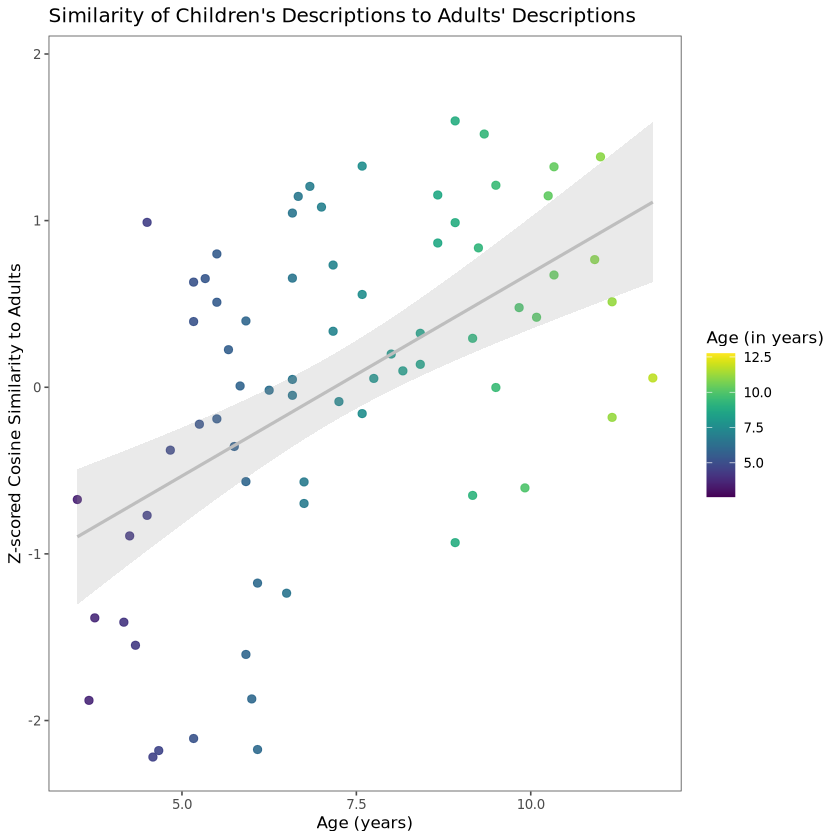

In [9]:
#Description accuracy (Fig 3B)
library(viridis)
p_desc <- ggplot(desc_avgs, aes(x = age_months/12,
                      y = description_similarity,
                      col = age_months/12)) +
  geom_point(size = 2, alpha = .9) +
  geom_smooth(method = "lm", color = "grey", alpha = .2) +
  scale_color_viridis(name = "Age (in years)", limits = c(age_min, age_max)) +
  scale_y_continuous(limits = c(y_min, y_max)) +
  labs(
    x = "Age (years)",
    y = "Z-scored Cosine Similarity to Adults",
    title = "Similarity of Children's Descriptions to Adults' Descriptions"
  ) +
  theme_few(base_size = 10)

p_desc
ggsave('../figures/cds_description_sim.png', width = 6, height = 3, units = 'in')

In [10]:
cat("Description plot n:", nrow(desc_avgs), "\n")

Description plot n: 72 


In [11]:
desc_model <- lmer(
  scale(utterance_full_cossim_adults)[, 1] ~ age_months + (1 | participant_id) + (1 | target_category),
  data = descriptions
)

summary(desc_model)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: scale(utterance_full_cossim_adults)[, 1] ~ age_months + (1 |  
    participant_id) + (1 | target_category)
   Data: descriptions

REML criterion at convergence: 1133.8

Scaled residuals: 
     Min       1Q   Median       3Q      Max 
-2.80605 -0.61587  0.07029  0.60980  2.25436 

Random effects:
 Groups          Name        Variance Std.Dev.
 participant_id  (Intercept) 0.1674   0.4091  
 target_category (Intercept) 0.0718   0.2680  
 Residual                    0.7006   0.8370  
Number of obs: 422, groups:  participant_id, 79; target_category, 6

Fixed effects:
             Estimate Std. Error        df t value Pr(>|t|)    
(Intercept) -0.962376   0.236602 49.346402  -4.067 0.000171 ***
age_months   0.010915   0.002339 74.626721   4.666 1.32e-05 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
           (Intr)
age_months -0.847

`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


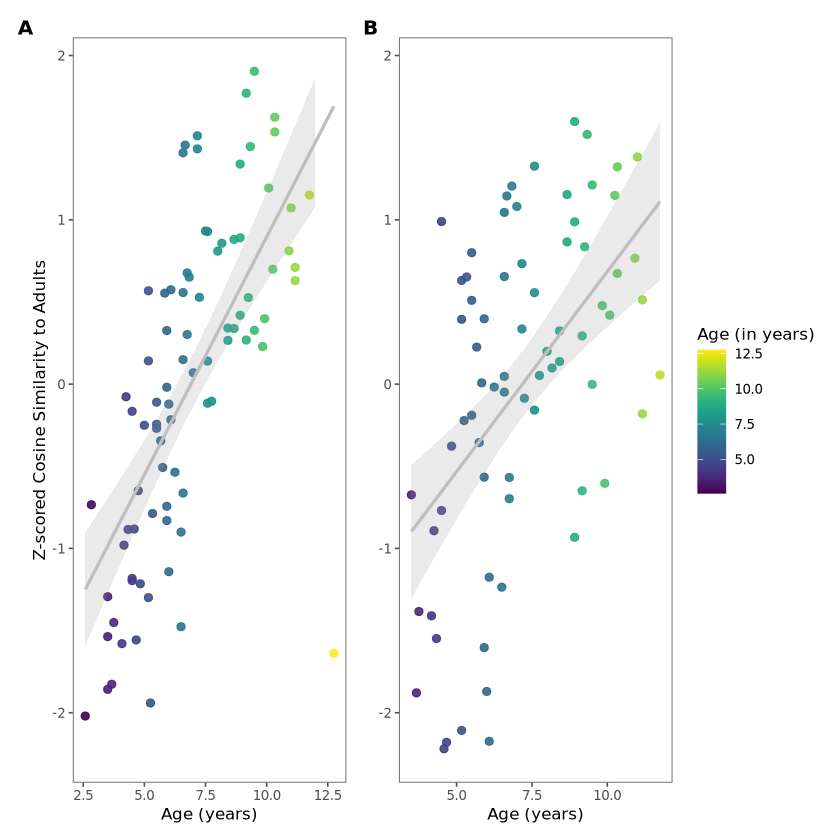

In [12]:
library(patchwork)
(p_draw + theme(legend.position = "none", plot.title = element_blank())) +
  (p_desc + theme(axis.title.y = element_blank(), plot.title = element_blank())) +
  plot_annotation(tag_levels = 'A') &
  theme(plot.tag = element_text(face = "bold"))

ggsave('../figures/fig3.png', width = 12, height = 4, units = 'in')

In [13]:
# Filter to child x category observations with both similarity values, z-score within modality
kids_both <- all_data_wide_kids %>%
  filter(!is.na(drawing_similarity), !is.na(description_similarity)) %>%
  mutate(
    drawing_sim_z = scale(drawing_similarity)[, 1],
    description_sim_z = scale(description_similarity)[, 1]
  )


`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'


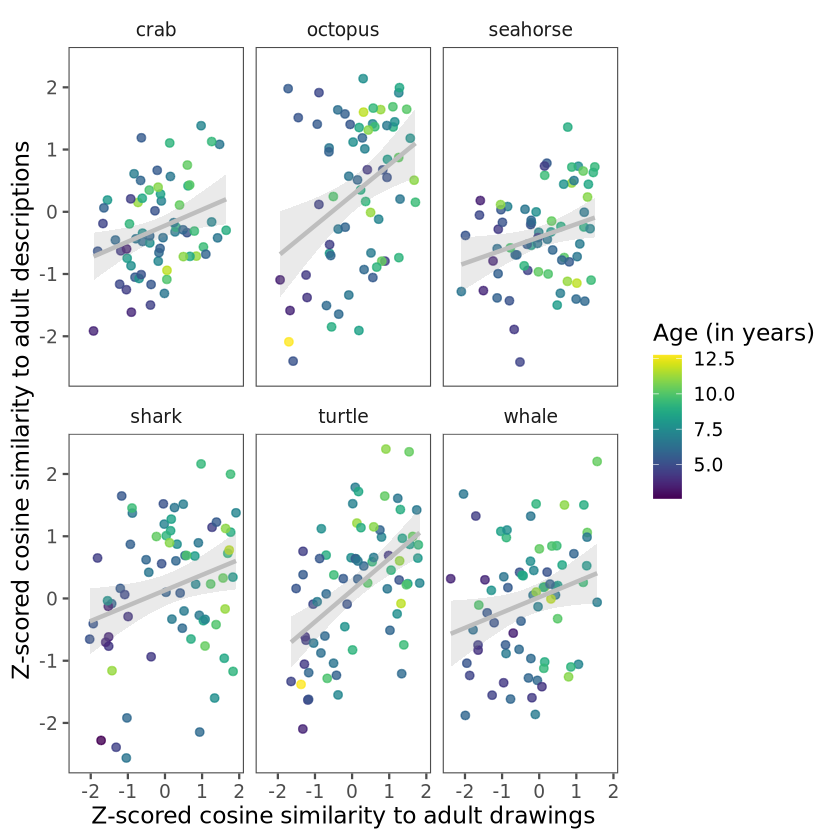

In [14]:

#Drawing vs description accuracy (Fig 4)
library(viridis)
ggplot(kids_both, aes(x = drawing_sim_z, y = description_sim_z, col = age_months/12)) +
  geom_point(alpha = .8) +
  scale_color_viridis(name = 'Age (in years)') +
  geom_smooth(method = 'lm', aes(group = category), color = 'grey', alpha = .2) +
  facet_wrap(~as.factor(category), ncol = 3) +
  ylab("Z-scored cosine similarity to adult descriptions") +
  xlab("Z-scored cosine similarity to adult drawings") +
  theme_few(base_size = 14)

ggsave('../figures/cds_similarity_by_age_by_category.png', width = 8, height = 5, units = 'in')

In [15]:
cat("Total observations:", nrow(kids_both), "\n")
cat("Number of children:", n_distinct(kids_both$sub_id), "\n\n")
kids_both %>% count(category)

Total observations: 411 
Number of children: 77 



category,n
<chr>,<int>
crab,66
octopus,67
seahorse,68
shark,69
turtle,71
whale,70


In [16]:
# Average z-scored similarity per child, then correlate
sub_avg_both <- kids_both %>%
  group_by(sub_id) %>%
  summarise(
    avg_drawing_sim_z = mean(drawing_sim_z, na.rm = TRUE),
    avg_description_sim_z = mean(description_sim_z, na.rm = TRUE),
    age_months = first(age_months),
    .groups = "drop"
  )

cor.test(sub_avg_both$avg_drawing_sim_z, sub_avg_both$avg_description_sim_z)


	Pearson's product-moment correlation

data:  sub_avg_both$avg_drawing_sim_z and sub_avg_both$avg_description_sim_z
t = 6.5156, df = 75, p-value = 7.403e-09
alternative hypothesis: true correlation is not equal to 0
95 percent confidence interval:
 0.4359253 0.7272530
sample estimates:
      cor 
0.6012038 


In [17]:
cor_by_category <- kids_both %>%
  group_by(category) %>%
  summarise(
    correlation = cor(drawing_sim_z, description_sim_z, use = "complete.obs"),
    p_value = cor.test(drawing_sim_z, description_sim_z)$p.value,
    n = n(),
    .groups = "drop"
  )

cor_by_category

category,correlation,p_value,n
<chr>,<dbl>,<dbl>,<int>
crab,0.3081443,1.183182e-02,66
octopus,0.3691271,2.112672e-03,67
seahorse,0.2679446,2.716568e-02,68
shark,0.2690316,2.539737e-02,69
turtle,0.5213089,3.141591e-06,71
whale,0.2508066,3.624082e-02,70


In [18]:
lmer_model <- lmer(
  drawing_sim_z ~ description_sim_z + scale(age_months) + (1 | sub_id) + (1 | category),
  data = kids_both
)

summary(lmer_model)

Linear mixed model fit by REML. t-tests use Satterthwaite's method [
lmerModLmerTest]
Formula: drawing_sim_z ~ description_sim_z + scale(age_months) + (1 |  
    sub_id) + (1 | category)
   Data: kids_both

REML criterion at convergence: 976.2

Scaled residuals: 
     Min       1Q   Median       3Q      Max 
-2.69302 -0.57604 -0.03149  0.62000  2.30382 

Random effects:
 Groups   Name        Variance Std.Dev.
 sub_id   (Intercept) 0.21110  0.4595  
 category (Intercept) 0.02079  0.1442  
 Residual             0.48583  0.6970  
Number of obs: 411, groups:  sub_id, 77; category, 6

Fixed effects:
                   Estimate Std. Error        df t value Pr(>|t|)    
(Intercept)        -0.01548    0.08652  12.17087  -0.179    0.861    
description_sim_z   0.17218    0.04194 396.33761   4.106 4.90e-05 ***
scale(age_months)   0.45541    0.06278  79.41983   7.254 2.38e-10 ***
---
Signif. codes:  0 ‘***’ 0.001 ‘**’ 0.01 ‘*’ 0.05 ‘.’ 0.1 ‘ ’ 1

Correlation of Fixed Effects:
            (Intr) d